<a href="https://colab.research.google.com/github/parvej-mosaraf/IRE-416-Computer-Vision-Sessional/blob/main/Assignment/Assignment%201/CV%20Assignment%2001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Assignment 1
```
Md. Parvej Mosaraf
Group: 02 ID: 2101024
Session: 2021-2022
Department of Internet of Things & Robotics Engineering (IRE)
University of Frontier Technology, Bangladesh
```



### Problem 1

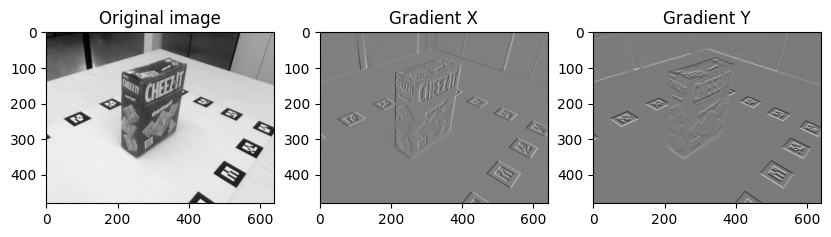

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

# main function
if __name__ == '__main__':

    # Step 1: read the cracker box image using cv2.imread
    url = 'https://github.com/parvej-mosaraf/IRE-416-Computer-Vision-Sessional/blob/main/Assignment/Assignment%201/cracker_box.jpg?raw=true'
    local_filename = 'cracker_box.jpg'
    try:
        # Download and save the image locally
        urllib.request.urlretrieve(url, local_filename)
        # Read the image using cv2.imread
        im = cv2.imread(local_filename)
    except Exception as e:
        print(f"Error downloading or reading image: {e}")
        im = None

    if im is not None:
        # Step 2: use cv2.cvtColor to convert RGB image to gray scale image
        gray_image = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

        # Step 3: use central difference to compute image gradient on the gray scale image
        # I(x+1, y) - I(x-1, y) / 2 and I(x, y+1) - I(x, y-1) / 2
        h, w = gray_image.shape
        gradient_x = np.zeros((h, w), dtype=np.float32)
        gradient_y = np.zeros((h, w), dtype=np.float32)

        # Use central difference on interior pixels
        gradient_x[:, 1:-1] = (gray_image[:, 2:].astype(np.float32) - gray_image[:, :-2].astype(np.float32)) / 2.0
        gradient_y[1:-1, :] = (gray_image[2:, :].astype(np.float32) - gray_image[:-2, :].astype(np.float32)) / 2.0

        # show result with matplotlib (no need to change code below)
        fig = plt.figure(figsize=(10, 5))
        ax = fig.add_subplot(1, 3, 1)
        plt.imshow(gray_image, cmap='gray')
        ax.set_title('Original image')

        ax = fig.add_subplot(1, 3, 2)
        plt.imshow(gradient_x, cmap='gray')
        ax.set_title('Gradient X')

        ax = fig.add_subplot(1, 3, 3)
        plt.imshow(gradient_y, cmap='gray')
        ax.set_title('Gradient Y')

        plt.show()
    else:
        print("Failed to load image correctly from the URL.")

### Problem 2

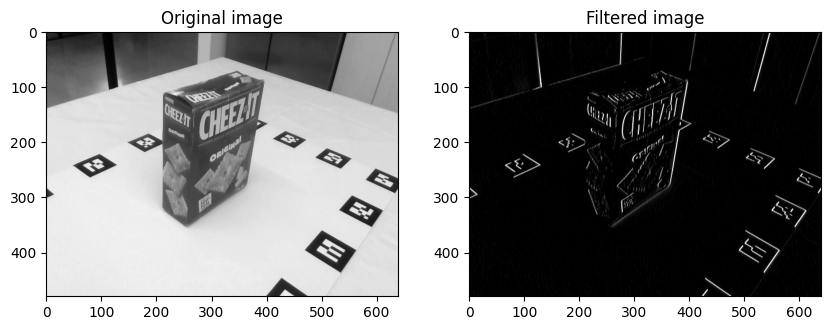

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

# main function
if __name__ == '__main__':

    # Step 1: read the cracker box image using cv2.imread
    url = 'https://github.com/parvej-mosaraf/IRE-416-Computer-Vision-Sessional/blob/main/Assignment/Assignment%201/cracker_box.jpg?raw=true'
    local_filename = 'cracker_box.jpg'
    try:
        # Download and save the image locally
        urllib.request.urlretrieve(url, local_filename)
        # Read the image using cv2.imread
        im = cv2.imread(local_filename)
    except Exception as e:
        print(f"Error downloading or reading image: {e}")
        im = None

    if im is not None:
        # Step 2: use cv2.cvtColor to convert RGB image to gray scale image
        gray_image = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

        # Step 3: define the filter kernel as described in the homework description as a numpy array
        kernel = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)

        # Step 4: filter the image with the kernel without direct cv2 filtering functions
        h, w = gray_image.shape
        output = np.zeros((h, w), dtype=np.float32)
        padded_img = np.pad(gray_image.astype(np.float32), 1, mode='edge')

        for r in range(h):
            for c in range(w):
                region = padded_img[r:r+3, c:c+3]
                output[r, c] = np.sum(region * kernel)

        # Clip values to valid range [0, 255] for visual presentation
        output = np.clip(output, 0, 255).astype(np.uint8)

        # show result with matplotlib (no need to change code below)
        fig = plt.figure(figsize=(10, 5))
        ax = fig.add_subplot(1, 2, 1)
        plt.imshow(gray_image, cmap='gray')
        ax.set_title('Original image')

        ax = fig.add_subplot(1, 2, 2)
        plt.imshow(output, cmap='gray')
        ax.set_title('Filtered image')

        plt.show()
    else:
        print("Failed to load image correctly.")